In [16]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [17]:
tickers = [
    "AAPL", "MSFT", "NVDA", "AMZN", "GOOGL",
    "META", "TSLA", "AVGO", "JPM", "LLY",
    "XOM", "NFLX", "COST", "AMD", "WMT",
    "UNH", "ORCL", "MA", "JNJ", "HD",
    "BAC", "ABBV", "KO", "PEP", "CRM",
    "ADBE", "CSCO", "TMO", "MCD", "LIN",
    "CVX", "MRK", "ACN", "ABT", "DHR",
    "QCOM", "TXN", "IBM", "GE", "INTU"
]

print(f"Total tickers: {len(tickers)}")

Total tickers: 40


In [18]:
data = yf.download(
    tickers,
    start="2024-01-01",
    auto_adjust=True,
    progress=False
)["Close"]

data = data.dropna(axis=1)

print(data.shape)

(600, 40)


In [19]:
momentum = (data.iloc[-1] / data.iloc[-60]) - 1

momentum = momentum.sort_values(ascending=False)

momentum.head(10)

Ticker
AMD      1.335098
QCOM     0.683683
CSCO     0.523565
TXN      0.465188
UNH      0.334914
ORCL     0.325659
AVGO     0.298729
AMZN     0.268191
GOOGL    0.229278
NVDA     0.215315
dtype: float64

In [20]:
returns = data.pct_change().dropna()

sharpe_ratios = (
    returns.mean() / returns.std()
) * np.sqrt(252)

sharpe_ratios = sharpe_ratios.sort_values(ascending=False)

sharpe_ratios.head(10)

Ticker
CSCO     1.695307
WMT      1.672409
GE       1.623929
GOOGL    1.577862
NVDA     1.530988
AVGO     1.366593
JPM      1.218675
JNJ      1.172672
AMD      1.166276
KO       1.087561
dtype: float64

In [21]:
results = pd.DataFrame({
    "Momentum_60D": momentum,
    "Sharpe_Ratio": sharpe_ratios
})

results = results.dropna()

results = results.sort_values(
    by="Momentum_60D",
    ascending=False
)

results.head(20)

,Momentum_60D,Sharpe_Ratio
Ticker,,
AMD,1.335098,1.166276
QCOM,0.683683,0.785941
CSCO,0.523565,1.695307
TXN,0.465188,0.951497
UNH,0.334914,-0.087285
ORCL,0.325659,0.776893
AVGO,0.298729,1.366593
AMZN,0.268191,0.930042
GOOGL,0.229278,1.577862


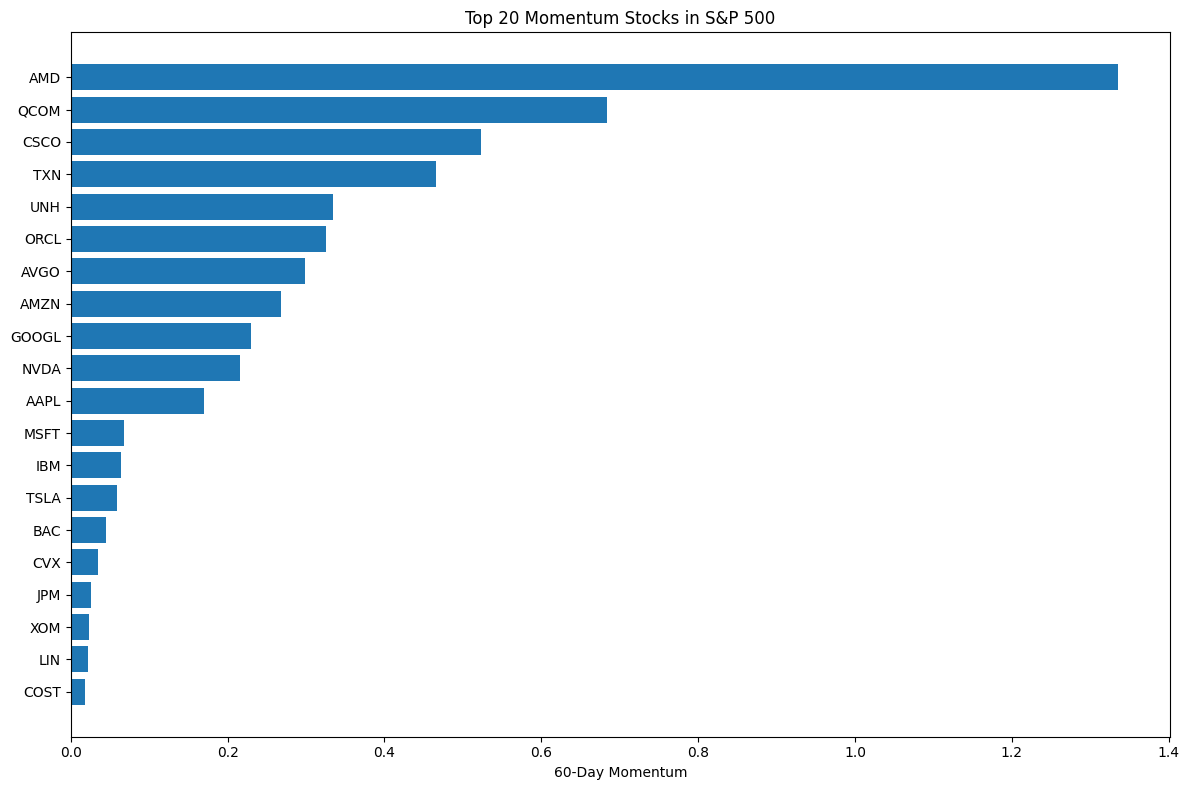

In [22]:
top20 = results.head(20)

plt.figure(figsize=(12, 8))

plt.barh(
    top20.index[::-1],
    top20["Momentum_60D"][::-1]
)

plt.xlabel("60-Day Momentum")
plt.title("Top 20 Momentum Stocks in S&P 500")

plt.tight_layout()

plt.show()

In [23]:
os.makedirs("output", exist_ok=True)

results.to_csv("output/momentum_ranking.csv")

print("CSV saved!")

CSV saved!


Chart saved!


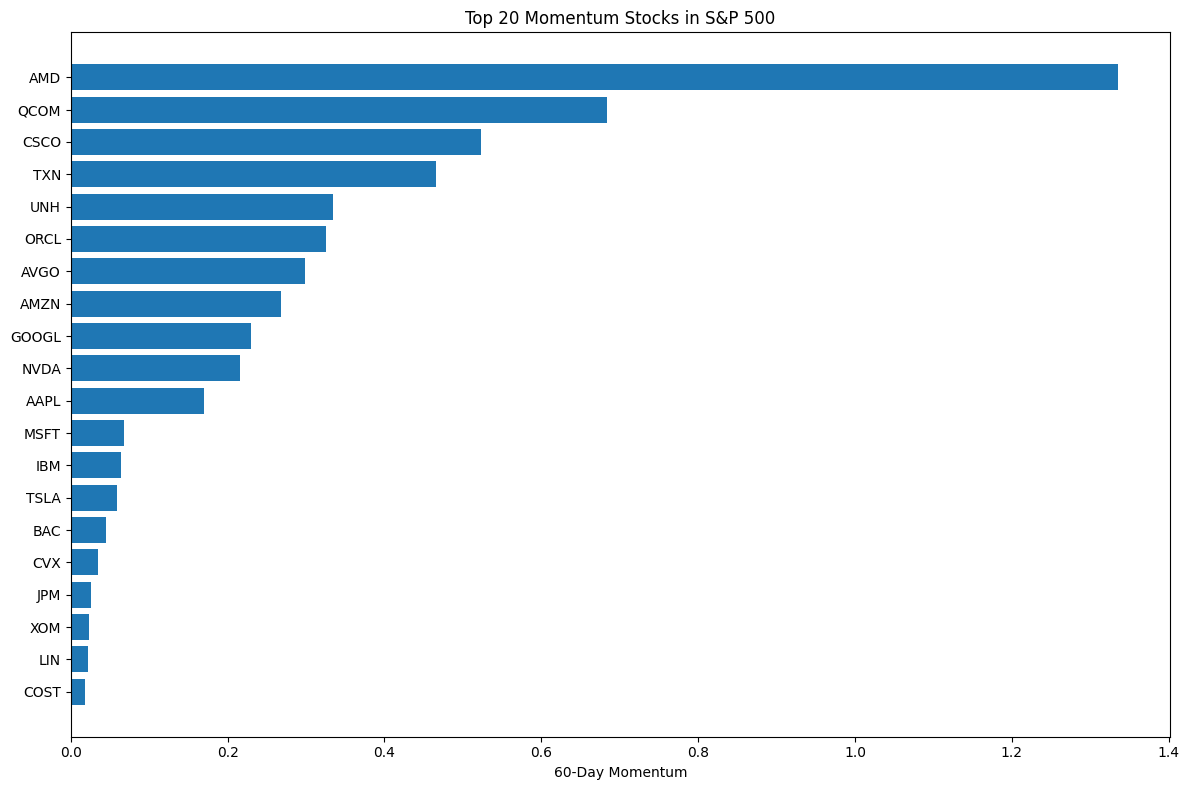

In [24]:
plt.figure(figsize=(12, 8))

plt.barh(
    top20.index[::-1],
    top20["Momentum_60D"][::-1]
)

plt.xlabel("60-Day Momentum")
plt.title("Top 20 Momentum Stocks in S&P 500")

plt.tight_layout()

plt.savefig("output/momentum_chart.png")

print("Chart saved!")